# ECSE 552 - Assignment 2, Part 2
**Group 2:** Ibrahim El Makhtoum, Milan Pickavet, Nathaniel Factor, Vijayarajan Singaraj

Run the cells in order in Colab or Jupyter. The saved outputs can be read without
running the code. The notebook contains all the code needed for this part.

In [1]:
%%capture
%pip install -q pytorch-lightning pandas matplotlib

In [2]:
# Paths and dataset download
from pathlib import Path
import urllib.request

# Plotting and numerical arrays
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd

# Model layers and data loaders
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

# Training, checkpoint selection and logging
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger

SEED = 552
pl.seed_everything(SEED, workers=True)
torch.set_num_threads(4)
plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})
print('PyTorch:', torch.__version__, '| Lightning:', pl.__version__)

PyTorch: 2.15.0 | Lightning: 2.6.6


## Conditional Variational Autoencoders

### Note

***Clearly comment each of your steps. Failure to do so would result in loss of points.***
**Additionally explain each line in your code**

### Introduction

Conditional Variational Autoencoders (CVAEs) are an extension of Variational Autoencoders (VAEs).

As we explored in tutorial eight, VAEs are comprised of two main parts: an encoder and a decoder.

The encoder approximates the function $Q(z|X)$ and the decoder approximates the function $P(X|z)$.

As a reminder, here $X$ is the input data and $z$ is a latent vector.

For more details, you might consider this [Tutorial on Variational Autoencoders](https://arxiv.org/abs/1606.05908) by Carl Doersch.

The above formulation, however, does not allow us to generate specific images. For example, given a model trained on the MNIST digits, it's difficult to fully explore the latent space for a given digit.

We can solve this by conditioning $P$ by not only the latent vector $z$, but some value $c$ that can encode information, (_e.g._: which MNIST digit we're generating).

This would mean our decoder would got from $P(X|z)$ in the VAE case to $P(X|z,c)$ in the CVAE case.

### Practical Implementation

Practically, this means that a "conditional" vector $c$ is passed to the decoder. This is commonly a class label for the sample that is one-hot encoded, but it can be anything you wish to marginalise the model by.

Below is a very high-level illustration of both a Variational Autoencoder (VAE) and a Conditional Variational Autoencoder (CVAE). Components of the CVAE that are not present in the VAE are demarked with a yellow star.

The CVAE is identical to the VAE, but for the concatenation of the vector $c$ to the vector $z$ before being inputted into the decoder. The loss function does not change in any way.

In this diagram the dimensions are noted for all the inputs and outputs of the Encoder and Decoder.

The dimension variables are as follows:

* $m$ is the batch size
* $w$ is the width of the image inputted into our encoder
* $h$ is the height of the image inputted into our encoder
* $n$ is the number of latent variables
* $q$ is the width of the conditional vector. If $c$ represents the class of the image, then $q$ is often equal to the number of classes.

<img src="https://ecse552.b-cdn.net/W24/H3/vae_cvae.webp" alt="VAE vs CVAE" width="50%"/>

Let's look closer at the concatenation of $z$ and $c$, as well as the representation of $c$. Consider the case of a CVAE where the samples are MNIST digits and $c$ is the one-hot encoded class of the digit. In this example, the number of latent variables ($n$ in the diagram above) is 3. Below is an illustration of what the concatenation might look like.

![Concatenating z with c](https://ecse552.b-cdn.net/W24/H3/conditional_z.webp)

The vectors that are the result of concatenating $z$ and $c$ (let's call it $z_c$) then become the input to the decoder.

### Q1.1 - Implementing an MNIST CVAE (10 points)

Your task is to extend the MNIST VAE from Tutorial 8 to a CVAE.

Specifically, you must:

1. Correctly define a conditional vector $c$ in the training loop.
2. Correctly concatenate it to $z$ to form $z_c$.
3. Input $z_c$ to the Decoder.
4. Make any further nescessary modifications to the code.

You are provided with the complete code for the MNIST VAE presented in Tutorial 8, including data loaders, encoders, decoders, and training/validation loops.

The number of latent variables for this excercise ($n$) is set to 10.

**Hint**: While you are permitted to make changes to the Encoder and Decoder class, it is not nescessary to correctly answer this question.

**Another Hint**: You can correctly answer this question by modifying/adding no more than six lines.

### Q1.1 - Changes to the model

The encoder still returns 10 means and 10 log variances. These are used to
sample $z$, which has shape $(B,10)$ for a batch of $B$ images.

I turn each digit label into a one-hot vector $c$ with 10 entries. For example,
label 2 becomes `[0,0,1,0,0,0,0,0,0,0]`. Joining $z$ and $c$ gives

$$z_c=[z\;c]\in\mathbb{R}^{B\times20}.$$

The decoder takes these 20 values and returns 784 pixels. Labels are passed
during training and validation. The encoder and decoder layers stay as supplied;
only the decoder's input width changes when it is created.

The loss is still reconstruction BCE plus KL divergence. BCE measures pixel
error, while KL keeps the encoded distribution close to a standard normal.
I divide both terms by the batch size when logging and optimizing, so the loss
is measured per image and their relative weights stay the same.

In [3]:
data_path = Path('sample_data/mnist_train_small.csv')
if not data_path.exists():
    # Use the same 20,000-image CSV as the Colab starter
    data_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        'https://download.mlcc.google.com/mledu-datasets/mnist_train_small.csv', data_path)

class MNISTDataset(Dataset):
    def __init__(self, csv_path):
        self.df = pd.read_csv(csv_path, header=None)  # every row is an image, not a header
        self.images = torch.from_numpy(
            self.df.iloc[:, 1:].to_numpy(dtype=np.float32, copy=True)) / 255.0  # pixels in [0,1]
        self.labels = torch.from_numpy(
            self.df.iloc[:, 0].to_numpy(dtype=np.int64, copy=True))  # integer digit labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

batch_size = 100
dataset = MNISTDataset(data_path)
num_test = len(dataset) // 10
num_train = len(dataset) - num_test
# Fix the split so results from this run can be reproduced
dataset_train, dataset_test = random_split(
    dataset, [num_train, num_test], generator=torch.Generator().manual_seed(SEED))
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0)
dataloader_test = DataLoader(dataset_test, batch_size=batch_size, shuffle=False,
    num_workers=0)  # keep the first batch the same for Q1.2 and Q1.3
print(f'Training: {num_train} images | Validation: {num_test} images')

Training: 18000 images | Validation: 2000 images


The CSV is loaded with `header=None` because it has no column-name row. The
90%/10% split gives 18,000 training images and 2,000 validation images. The name
`dataloader_test` is kept from the starter, but this split is used for validation
and early stopping rather than as an untouched test set.

In [4]:
class Encoder(nn.Module):
    def __init__(self, in_dim, latent_dim):
        super(Encoder, self).__init__()

        # Layer widths and pooling are kept from the starter
        self.layer0 = nn.Linear(in_dim, 1024)
        self.layer1 = nn.Linear(512, 768)
        self.layer2 = nn.Linear(768, 1024)
        self.layer3 = nn.Linear(512, 256)
        self.layer4 = nn.Linear(128, latent_dim)

        self.pool = nn.MaxPool1d(2)

        self.dropout = nn.Dropout(0.3)

        self.activation = nn.LeakyReLU(0.01)

    def forward(self, x):

        # Extract image features, reducing their width with pooling
        x = self.layer0(x)
        x = self.activation(x)

        x = self.dropout(x)

        x = x.reshape(x.shape[0], 1, x.shape[1])
        x = self.pool(x)
        x = x.reshape(x.shape[0], x.shape[2])

        x = self.layer1(x)
        x = self.activation(x)

        x = self.dropout(x)

        x = self.layer2(x)
        x = self.activation(x)

        x = self.dropout(x)

        x = x.reshape(x.shape[0], 1, x.shape[1])
        x = self.pool(x)
        x = x.reshape(x.shape[0], x.shape[2])

        x = self.layer3(x)
        x = self.activation(x)

        x = self.dropout(x)

        x = x.reshape(x.shape[0], 1, x.shape[1])
        x = self.pool(x)
        x = x.reshape(x.shape[0], x.shape[2])

        # Output the parameters for mu and log variance
        x = self.layer4(x)
        x = self.activation(x)

        return x

In [5]:
class Decoder(nn.Module):
    def __init__(self, latent_dim, out_dim):
        super(Decoder, self).__init__()

        self.layer4 = nn.Linear(784, out_dim)
        self.layer3 = nn.Linear(768, 784)
        self.layer2 = nn.Linear(1024, 768)
        self.layer1 = nn.Linear(256, 1024)
        self.layer0 = nn.Linear(latent_dim, 256)

        self.dropout = nn.Dropout(0.3)

        self.activation = nn.LeakyReLU(0.01)

    def forward(self, x):

        # Decode the latent vector and label through the hidden layers
        x = self.layer0(x)
        x = self.activation(x)

        x = self.dropout(x)

        x = self.layer1(x)
        x = self.activation(x)

        x = self.dropout(x)

        x = self.layer2(x)
        x = self.activation(x)

        x = self.dropout(x)

        x = self.layer3(x)
        x = self.activation(x)

        x = self.dropout(x)

        x = self.layer4(x)
        x = torch.sigmoid(x)  # pixel values in [0,1] for BCE

        return x

In [6]:
class MNIST_VAE(pl.LightningModule):
    def __init__(self, in_dim, out_dim, latent_dim):
        super(MNIST_VAE, self).__init__()

        self.latent_dim = latent_dim

        self.encoder = Encoder(in_dim, latent_dim*2)
        self.decoder = Decoder(latent_dim + 10, out_dim)  # z plus the 10 label entries
        self.recon_criterion = nn.BCELoss(reduction='sum')

    def reparameterize(self, mu, log_var):
        # Sample z while keeping gradients through mu and log_var
        std = torch.exp(0.5*log_var)
        eps = torch.randn_like(std)
        return eps.mul(std).add_(mu)

    def loss(self, mu, logvar, pred, target):

        # Sum reconstruction BCE and Gaussian KL over the batch
        kld_loss = torch.sum(-0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp(), dim = 1), dim = 0)
        recons_loss = self.recon_criterion(pred, target)

        loss = recons_loss + kld_loss

        return kld_loss, recons_loss, loss

    def forward(self, x, y):

        parameters= self.encoder(x)

        mu = parameters[:, :self.latent_dim]
        logvar = parameters[:, self.latent_dim:]

        z = self.reparameterize(mu, logvar)

        c = F.one_hot(y.long(), num_classes=10).to(z)  # (B,) -> (B,10), matching z's dtype/device
        x_hat = self.decoder(torch.cat((z, c), dim=1))  # (B,20) -> (B,784)

        return mu, logvar, z, x_hat

    def training_step(self, batch, batch_idx):

        x, y = batch

        mu, logvar, z, x_hat = self(x, y)  # condition on the true labels

        kld_loss, recons_loss, loss = self.loss(mu, logvar, x_hat, x)

        # Log the objective and its two terms per image
        self.log('training_loss', loss / x.shape[0], on_step=False, on_epoch=True, batch_size=x.shape[0])
        self.log('training_kld_loss', kld_loss / x.shape[0], on_step=False, on_epoch=True, batch_size=x.shape[0])
        self.log('training_recons_loss', recons_loss / x.shape[0], on_step=False, on_epoch=True, batch_size=x.shape[0])
        return loss / x.shape[0]

    def validation_step(self, batch, batch_idx):

        x, y = batch

        mu, logvar, z, x_hat = self(x, y)  # condition on the true labels

        kld_loss, recons_loss, loss = self.loss(mu, logvar, x_hat, x)

        self.log('val_loss', loss / x.shape[0], on_step=False, on_epoch=True, batch_size=x.shape[0])
        self.log('val_kld_loss', kld_loss / x.shape[0], on_step=False, on_epoch=True, batch_size=x.shape[0])
        self.log('val_recons_loss', recons_loss / x.shape[0], on_step=False, on_epoch=True, batch_size=x.shape[0])
        return loss / x.shape[0]

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=1e-3)
        return optimizer

### Training
I keep Adam at the starter learning rate of 0.001 and the original early-stopping
settings: patience 3 and minimum improvement 0.0001, with at most 40 epochs.
The optional OneCycleLR is removed because its 20-epoch schedule did not match
the training limit and it was not configured to update after each batch.

The logger saves the loss history. I use the checkpoint with the lowest
validation loss for the reconstruction plots. The checkpoint is created during
training; it does not need to be included with this notebook.

In [7]:
# Set up the model and record the loss history
model = MNIST_VAE(784, 784, 10)
logger = CSVLogger('training_logs', name='part2')
# Stop after three epochs without a validation improvement
early_stopping = EarlyStopping('val_loss', verbose=True, min_delta=0.0001, patience=3)
checkpoint = ModelCheckpoint(monitor='val_loss', mode='min', save_top_k=1,
    save_weights_only=True, filename='best')  # retain the best validation epoch
# Select an available device and keep the 40-epoch limit
trainer = pl.Trainer(accelerator='auto', devices=1, logger=logger,
    callbacks=[early_stopping, checkpoint], max_epochs=40,
    enable_progress_bar=False, enable_model_summary=False, num_sanity_val_steps=0)
# Fit on training images and monitor the held-out split
trainer.fit(model, dataloader_train, dataloader_test)

logger.save()
# Training and validation may be logged on separate rows for the same epoch
metrics = pd.read_csv(Path(logger.log_dir) / 'metrics.csv')
history = metrics.groupby('epoch', as_index=False).last()
history['epoch'] = history['epoch'].astype(int) + 1
best_row = history.loc[history['val_loss'].idxmin()]
# Use the best checkpoint, rather than the model from the last training epoch
model = MNIST_VAE.load_from_checkpoint(checkpoint.best_model_path,
    in_dim=784, out_dim=784, latent_dim=10, map_location='cpu')
model.eval()  # turn off dropout for the reconstruction plots
print(f"Completed {len(history)} epochs; best epoch: {int(best_row['epoch'])}")
print(f"Validation loss per image: {best_row['val_loss']:.3f} "
      f"(BCE {best_row['val_recons_loss']:.3f}, KL {best_row['val_kld_loss']:.3f})")

Completed 11 epochs; best epoch: 8
Validation loss per image: 149.492 (BCE 147.451, KL 2.042)


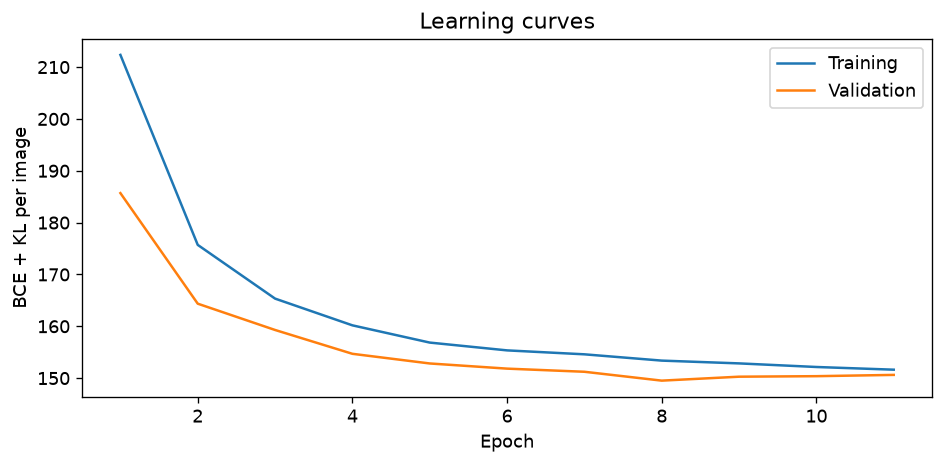

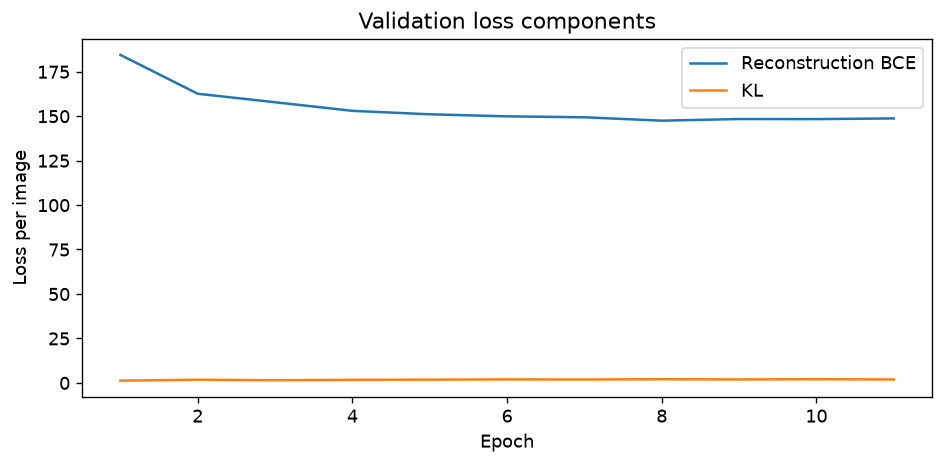

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history['epoch'], history['training_loss'], label='Training')
ax.plot(history['epoch'], history['val_loss'], label='Validation')
ax.set(xlabel='Epoch', ylabel='BCE + KL per image', title='Learning curves')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
fig.tight_layout()
plt.show()

# Separate the two parts of the validation objective
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history['epoch'], history['val_recons_loss'], label='Reconstruction BCE')
ax.plot(history['epoch'], history['val_kld_loss'], label='KL')
ax.set(xlabel='Epoch', ylabel='Loss per image', title='Validation loss components')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
fig.tight_layout()
plt.show()

### Q1.2 Demonstrate Reconstruction (5 points)

In the same way as was demonstrated in Tutorial 8, the ability of your model to reconstruct the first two digits from the first batch provided by `dataloader_test`.

Specifically, pass the first two values of `x` and `y` from `dataloader_test` to `model` and reconstruct these images. Plot them as illustrated below:

<img src=https://ecse552.b-cdn.net/W24/H3/q1.2.webp alt="Reconstructed MNIST digits" width="35%"/>

**Note**: The batches are randomised so you won't nescessarily get the same samples shown above.

### Q1.2 - Reconstruction
I take the first two images and labels from the first held-out batch and
reconstruct them with their correct labels. Evaluation mode turns off dropout.
I keep the sampled latent vectors for Q1.3.

Decoder input shape: (2, 20)


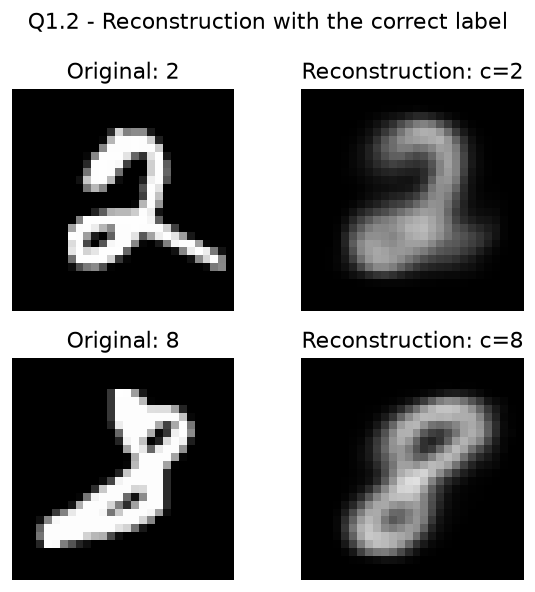

In [9]:
x, y = next(iter(dataloader_test))
demo_x, demo_y = x[:2], y[:2]  # the required first two examples
torch.manual_seed(SEED + 1)  # fix the sample used in both questions
model.eval()
with torch.no_grad():
    mu, logvar, demo_z, reconstructed = model(demo_x, demo_y)
    c = F.one_hot(demo_y, num_classes=10).to(demo_z)
    print('Decoder input shape:', tuple(torch.cat((demo_z, c), dim=1).shape))

fig, axes = plt.subplots(2, 2, figsize=(5, 5))
for i in range(2):
    # One original and its reconstruction on each row
    axes[i, 0].imshow(demo_x[i].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    axes[i, 0].set_title(f'Original: {demo_y[i].item()}')
    axes[i, 1].imshow(reconstructed[i].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    axes[i, 1].set_title(f'Reconstruction: c={demo_y[i].item()}')
    for ax in axes[i]:
        ax.axis('off')
fig.suptitle('Q1.2 - Reconstruction with the correct label')
fig.tight_layout()
plt.show()

### Q1.3 Demonstrate Conditional Reconstruction (5 points)

Similar to Q1.2, reconstruct digits, but instead of using the correct $c$ vector, change the class label to a different one.

For example, the value of `y` for the two samples below are 3 and 6, but when reconstructing, the $c$ vector `[0,0,1,0,0,0,0,0,0,0]` was supplied.

<img src="https://ecse552.b-cdn.net/W24/H3/q1.3.png" alt="Conditioned Reconstruction" width="35%"/>

### Q1.3 - Changing the label
I replace each label with $(y+1)\bmod10$ and keep the same latent vector from
Q1.2. This changes only the condition, rather than drawing a different random
sample of $z$.

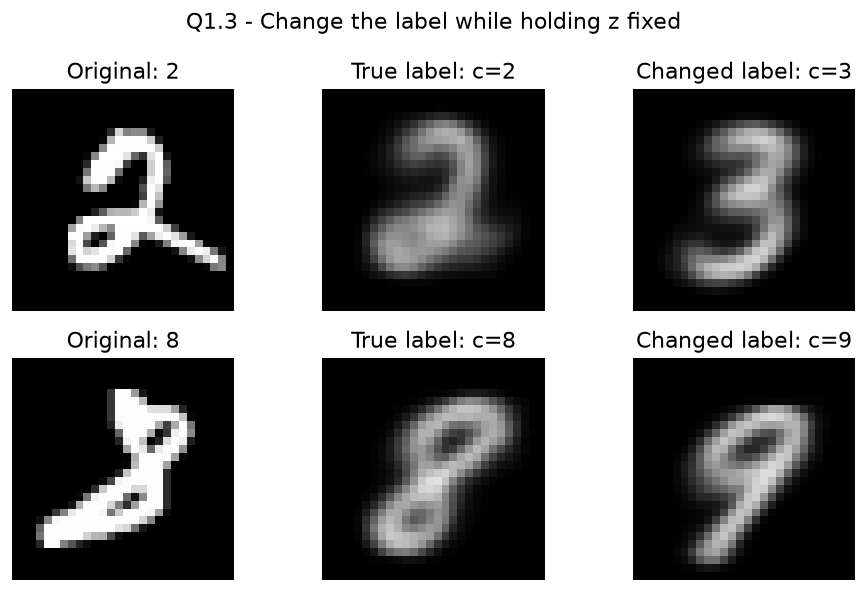

Original labels: [2, 8] | Changed labels: [3, 9]


In [10]:
changed_y = (demo_y + 1) % 10  # always different from the original class
with torch.no_grad():
    changed_c = F.one_hot(changed_y, num_classes=10).to(demo_z)
    # Same z as Q1.2, with the replacement labels
    changed_images = model.decoder(torch.cat((demo_z, changed_c), dim=1))

fig, axes = plt.subplots(2, 3, figsize=(8, 5))
for i in range(2):
    images = [demo_x[i], reconstructed[i], changed_images[i]]
    titles = [f'Original: {demo_y[i].item()}', f'True label: c={demo_y[i].item()}',
              f'Changed label: c={changed_y[i].item()}']
    # Compare the original, correct-label output, and changed-label output
    for j in range(3):
        axes[i, j].imshow(images[j].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
        axes[i, j].set_title(titles[j])
        axes[i, j].axis('off')
fig.suptitle('Q1.3 - Change the label while holding z fixed')
fig.tight_layout()
plt.show()
print('Original labels:', demo_y.tolist(), '| Changed labels:', changed_y.tolist())

## Results
Training stopped after 11 epochs. The lowest validation loss was at
epoch 8: 149.492 per image,
with 147.451 BCE and 2.042 KL.

The first two held-out images are a 2 and an 8. Their reconstructions retain the
digit classes but lose handwriting details. In particular, the reconstructed 8
does not fully preserve the original skew and stroke detail. Changing the labels to 3 and 9 while
holding the latent vectors fixed gives outputs shaped like the requested digits.
This shows label control on these examples, not an accuracy score for the dataset.

Training loss can be higher than validation loss because dropout is active
during training. It also averages predictions made while the weights are still
changing, whereas validation uses the weights at the end of the epoch.

The held-out split was used for checkpoint selection, so it is not an untouched final test set.


### References
- Course Assignment 2 Part 2 notebook and Tutorial 8 VAE code.
- [MNIST CSV](https://download.mlcc.google.com/mledu-datasets/mnist_train_small.csv).
- [Lightning Trainer](https://lightning.ai/docs/pytorch/stable/core-api/trainer).